# CalçadaLivre — Data Science & Statistical Computing

**Global Solution 2026.2 · FIAP · Engenharia de Software · CitizenTech**

| RM | Nome |
|---|---|
| RM562159 | Bruno Costa Scuciato |
| RM566222 | Luiz Fernando Balbino |
| RM561613 | Gustavo Torres Caldeira |

## 1. Contexto

A **CalçadaLivre** indica a rota mais acessível para **pessoas com deficiência física, idosos e mães e pais com carrinho de bebê**.
O trajeto estudado vai da **Estação Suzano (CPTM, Linha 11-Coral)** até a **Santa Casa de Suzano** (Rua Professor Roberto David, 499, Vila Figueira).
A rota mais curta tem cerca de **2.080 m**, e boa parte dela passa por calçadas **estreitas, ocupadas pelo comércio e com piso quebrado**.
Quem usa cadeira de rodas ou empurra um carrinho acaba descendo para a rua, entre os carros.

No módulo de *Dynamic Programming*, o app modela o trajeto como um grafo e escolhe a rota com o algoritmo de Dijkstra.
O custo de cada trecho depende de um **índice de acessibilidade (0 a 100)**, e o app precisa saber se o trecho é **intransitável** para cadeira de rodas.
Este notebook cria os dois modelos que geram essas informações.

## 2. Perguntas e variáveis-alvo

| # | Pergunta | Modelo | Variável-alvo |
|---|---|---|---|
| 1 | Qual é o **índice de acessibilidade** de um trecho de calçada, a partir das suas características físicas? | Regressão linear | `indice_acessibilidade` (numérica, 0 a 100) |
| 2 | Qual é a **probabilidade de o trecho ser intransitável** para cadeira de rodas? | Regressão logística | `intransitavel_cadeira` (binária: 1 = o avaliador em cadeira de rodas não conseguiu passar) |

**Hipótese a testar:** trechos ocupados pelo comércio (mesas, mercadorias, barracas) têm índice de acessibilidade menor do que os trechos livres.

**Decisão que os modelos apoiam:** qual rota indicar para cada perfil e **quais trechos a prefeitura deve reformar primeiro**. Essa priorização é a mochila 0/1 do módulo de DP.

## 3. Base de dados

**Arquivo:** `calcadas_suzano.csv` (650 linhas, 18 colunas). Cada linha é um trecho de calçada do entorno entre a Estação Suzano e a Santa Casa.

**Fonte:** base **simulada** pelo grupo (dados sintéticos gerados pelo script `gerar_base.py`, enviado junto).
Os valores seguem a **ABNT NBR 9050:2020**, que pede faixa livre mínima de 1,20 m na calçada, e as condições observadas no trajeto.
Os dados imitam uma **auditoria de campo**: o avaliador mede a calçada, dá uma nota de acessibilidade e tenta passar de cadeira de rodas.
A base **não contém dados pessoais**. Na versão final, as linhas podem ser trocadas por uma auditoria real, mantendo o mesmo formato.

| Coluna | Descrição |
|---|---|
| `rua`, `bairro`, `tipo_via` | rua, bairro e tipo de via (local, coletora, arterial). As calçadas **não têm a mesma largura**: cada rua tem uma largura típica, e ela também varia de um trecho para outro da mesma rua |
| `comprimento_m` | comprimento do trecho |
| `largura_total_m`, `largura_livre_m` | largura da calçada e largura que sobra livre para passar |
| `inclinacao_pct` | inclinação longitudinal (%) |
| `buracos` | estado do piso: 0 = bom ... 3 = muito quebrado |
| `tem_degrau` | existe degrau ou desnível no trecho (0/1) |
| `obstaculos_100m` | postes, lixeiras, placas etc. a cada 100 m |
| `ocupado_comercio` | calçada parcialmente tomada pelo comércio (0/1) |
| `rampa_esquina`, `piso_tatil` | existe rampa na esquina / piso tátil (0/1) |
| `idade_calcada_anos` | anos desde a última reforma |
| `fluxo_pedestres_hora` | pedestres por hora no pico |
| `indice_acessibilidade` | **alvo 1**: nota de acessibilidade dada na avaliação (0 a 100) |
| `intransitavel_cadeira` | **alvo 2**: 1 se o avaliador em cadeira de rodas não conseguiu passar |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score, roc_auc_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
SEED = 42

In [2]:
df = pd.read_csv("calcadas_suzano.csv")
print("Formato:", df.shape)
df.head()

Formato: (650, 18)


,id_trecho,rua,bairro,tipo_via,comprimento_m,largura_total_m,largura_livre_m,inclinacao_pct,buracos,tem_degrau,obstaculos_100m,ocupado_comercio,rampa_esquina,piso_tatil,idade_calcada_anos,fluxo_pedestres_hora,indice_acessibilidade,intransitavel_cadeira
0,T0001,Rua Felício de Camargo,Centro,coletora,178,1.88,1.61,6.5,0,0,1,0,0,0,13,148,85.1,0
1,T0002,Av. Armando Salles de Oliveira,Parque Suzano,arterial,72,2.64,2.49,9.1,2,0,1,0,1,0,18,89,83.4,0
2,T0003,Av. Antônio Marques Figueira,Vila Figueira,arterial,75,2.76,2.40,NaN,1,0,3,0,0,1,27,101,76.2,0
3,T0004,Av. Antônio Marques Figueira,Vila Figueira,arterial,175,2.60,2.59,11.2,0,0,0,0,1,0,10,108,80.8,0
4,T0005,Rua Benjamin Constant,Centro,local,40,1.08,0.40,6.0,1,0,4,1,0,1,27,99,19.9,1


## 4. Preparação dos dados

Primeiro tratamos os problemas **de cada linha**, que não usam estatísticas da base inteira. Por isso podem ser feitos antes da divisão sem vazamento:

1. texto fora do padrão em `bairro` (por exemplo `"centro "`);
2. linhas duplicadas;
3. valores impossíveis: largura livre maior que a largura total, que é erro de digitação, como 12,0 no lugar de 1,20.

Os **valores faltantes** são preenchidos com a mediana **dentro do pipeline**. Assim, a mediana é calculada só com os dados de treino.

In [3]:
print("Valores faltantes por coluna:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nBairros antes:", sorted(df["bairro"].unique()))

df["bairro"] = df["bairro"].str.strip().str.title()
print("Bairros depois:", sorted(df["bairro"].unique()))

dup = df.duplicated().sum()
df = df.drop_duplicates()
print(f"\nDuplicadas removidas: {dup}")

invalidas = df["largura_livre_m"] > df["largura_total_m"]
print(f"Linhas com largura livre > largura total (erro de digitação): {invalidas.sum()}")
print(df.loc[invalidas, ["id_trecho", "largura_total_m", "largura_livre_m"]])
df = df[~invalidas].reset_index(drop=True)
print("\nFormato final:", df.shape)

Valores faltantes por coluna:
largura_livre_m    14
inclinacao_pct     14
dtype: int64

Bairros antes: ['Centro', 'Jardim Paulista', 'Jardim Santa Helena', 'Parque Suzano', 'Vila Costa', 'Vila Figueira', 'centro ']
Bairros depois: ['Centro', 'Jardim Paulista', 'Jardim Santa Helena', 'Parque Suzano', 'Vila Costa', 'Vila Figueira']

Duplicadas removidas: 10
Linhas com largura livre > largura total (erro de digitação): 3
    id_trecho  largura_total_m  largura_livre_m
517     T0518             2.25             11.0
552     T0553             2.04             15.0
620     T0621             2.60             12.0

Formato final: (637, 18)


### 4.1 Divisão entre treino e teste

A divisão é feita **antes** de qualquer análise ou ajuste: 80% treino e 20% teste, estratificada pelo alvo binário para manter a mesma proporção de trechos intransitáveis.
A análise exploratória e o teste de hipótese usam **só o treino**. O conjunto de teste fica guardado até a avaliação final.

Para evitar vazamento, também separamos as variáveis de entrada de cada modelo:
- a coluna `id_trecho` é só um identificador e não entra;
- a coluna `rua` também não entra: o modelo deve funcionar para **qualquer rua**, inclusive as que ainda não estão na base. Por isso ele aprende com as características físicas (largura, piso, inclinação...), e não com o nome da rua. Se o nome entrasse, o modelo apenas decoraria as ruas da amostra;
- o modelo **linear** não usa `intransitavel_cadeira`, e o modelo **logístico** não usa `indice_acessibilidade`. Os dois alvos vêm da mesma avaliação de campo, então usar um para prever o outro seria usar uma informação que não existe quando o trecho ainda não foi avaliado.

In [4]:
ALVO_NUM, ALVO_BIN = "indice_acessibilidade", "intransitavel_cadeira"
CATEGORICAS = ["bairro", "tipo_via"]
# largura_total_m fica de fora: é muito correlacionada com a largura livre (multicolinearidade) e o que
# determina a passagem é a faixa LIVRE. Com as duas no modelo, o efeito se divide e os coeficientes perdem o sentido.
NUMERICAS = ["comprimento_m", "largura_livre_m", "inclinacao_pct", "buracos",
             "tem_degrau", "obstaculos_100m", "ocupado_comercio", "rampa_esquina", "piso_tatil",
             "idade_calcada_anos", "fluxo_pedestres_hora"]
X = df[CATEGORICAS + NUMERICAS]
y_num, y_bin = df[ALVO_NUM], df[ALVO_BIN]

X_treino, X_teste, yn_treino, yn_teste, yb_treino, yb_teste = train_test_split(
    X, y_num, y_bin, test_size=0.2, random_state=SEED, stratify=y_bin)

print(f"Treino: {len(X_treino)} trechos | Teste: {len(X_teste)} trechos")
print(f"% intransitável — treino: {yb_treino.mean():.1%} | teste: {yb_teste.mean():.1%}")

Treino: 509 trechos | Teste: 128 trechos
% intransitável — treino: 45.0% | teste: 44.5%


## 5. Análise exploratória (somente treino)

### 5.1 As calçadas não têm a mesma largura

Cada rua tem uma largura típica de calçada, e a largura também muda ao longo da mesma rua (comércio, postes, árvores).
O gráfico abaixo mostra a **largura livre por rua**, ordenada da mais estreita para a mais larga.

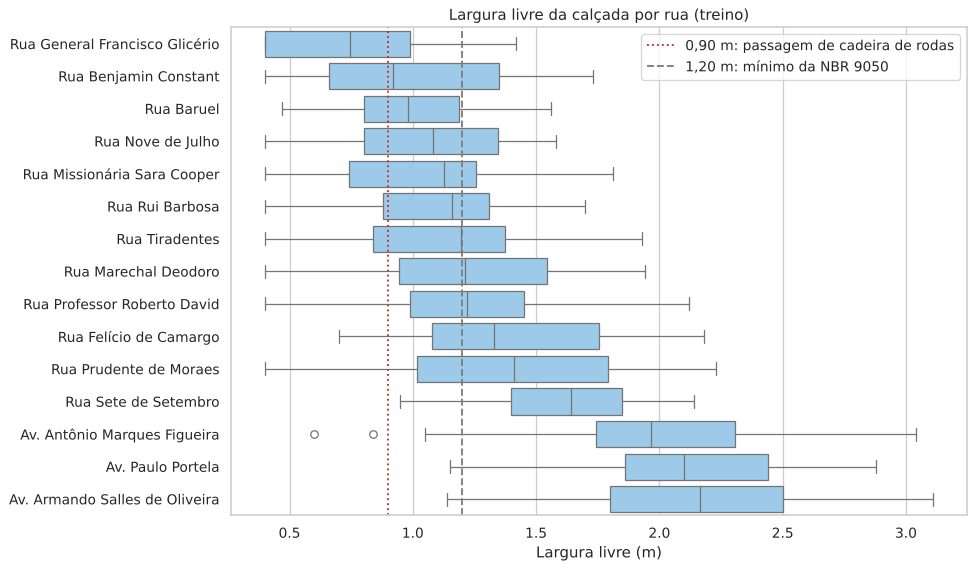

,trechos,largura_livre_mediana,abaixo_de_1_20,intransitavel
rua,,,,
Rua General Francisco Glicério,45,0.74,0.87,0.84
Rua Benjamin Constant,33,0.92,0.70,0.58
Rua Baruel,34,0.98,0.76,0.68
Rua Nove de Julho,28,1.08,0.64,0.61
Rua Missionária Sara Cooper,25,1.12,0.60,0.72
Rua Rui Barbosa,28,1.16,0.57,0.64
Rua Tiradentes,30,1.19,0.50,0.27
Rua Marechal Deodoro,32,1.21,0.47,0.50
Rua Professor Roberto David,26,1.22,0.46,0.54


In [5]:
treino_rua = df.loc[X_treino.index]
ordem = treino_rua.groupby("rua")["largura_livre_m"].median().sort_values().index
plt.figure(figsize=(11, 6.5))
sns.boxplot(data=treino_rua, y="rua", x="largura_livre_m", order=ordem, color="#90cdf4")
plt.axvline(0.90, ls=":", c="#c53030", label="0,90 m: passagem de cadeira de rodas")
plt.axvline(1.20, ls="--", c="gray", label="1,20 m: mínimo da NBR 9050")
plt.xlabel("Largura livre (m)"); plt.ylabel(""); plt.legend(loc="upper right")
plt.title("Largura livre da calçada por rua (treino)"); plt.tight_layout(); plt.show()

resumo_rua = (treino_rua.groupby("rua")
              .agg(trechos=("id_trecho", "count"), largura_livre_mediana=("largura_livre_m", "median"),
                   abaixo_de_1_20=("largura_livre_m", lambda s: (s < 1.20).mean()),
                   intransitavel=("intransitavel_cadeira", "mean"))
              .sort_values("largura_livre_mediana").round(2))
resumo_rua

**Leitura:** as ruas do comércio do Centro (Rua General Francisco Glicério) e a Rua Baruel, na Vila Figueira, têm as calçadas mais estreitas. Na maior parte dos trechos dessas ruas, a largura livre fica abaixo de 1,20 m, e a proporção de trechos intransitáveis é a mais alta.
As avenidas (Antônio Marques Figueira, Armando Salles de Oliveira e Paulo Portela) têm calçadas bem mais largas.
É por isso que a rota acessível da CalçadaLivre troca as ruas estreitas pela Av. Antônio Marques Figueira, mesmo sendo mais longa.

### 5.2 Relação entre as variáveis

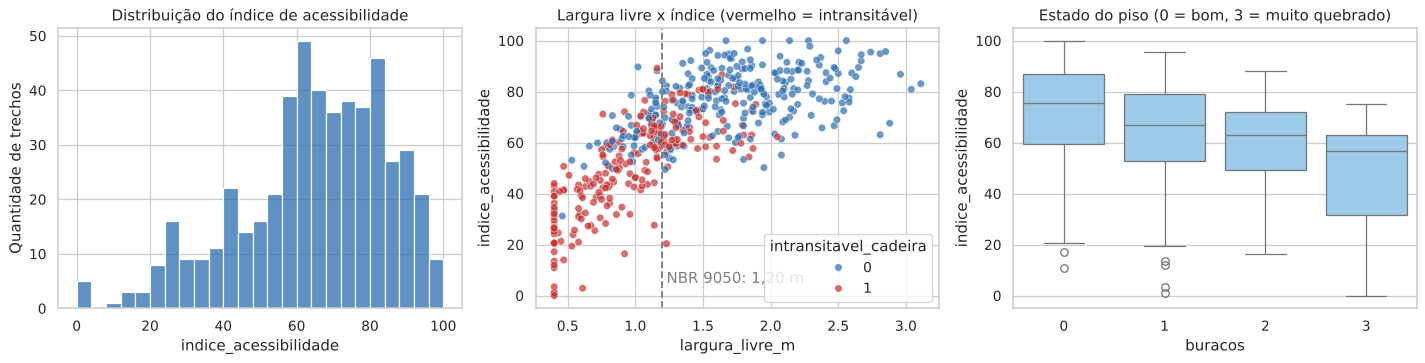

In [6]:
treino = X_treino.assign(indice_acessibilidade=yn_treino, intransitavel_cadeira=yb_treino)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(treino[ALVO_NUM], bins=25, ax=ax[0], color="#2b6cb0")
ax[0].set_title("Distribuição do índice de acessibilidade"); ax[0].set_ylabel("Quantidade de trechos")
sns.scatterplot(data=treino, x="largura_livre_m", y=ALVO_NUM, hue=ALVO_BIN, ax=ax[1],
                palette={0: "#2b6cb0", 1: "#c53030"}, alpha=0.7)
ax[1].axvline(1.20, ls="--", c="gray"); ax[1].text(1.23, 5, "NBR 9050: 1,20 m", color="gray")
ax[1].set_title("Largura livre x índice (vermelho = intransitável)")
sns.boxplot(data=treino, x="buracos", y=ALVO_NUM, ax=ax[2], color="#90cdf4")
ax[2].set_title("Estado do piso (0 = bom, 3 = muito quebrado)")
plt.tight_layout(); plt.show()

Correlação com o índice de acessibilidade:
obstaculos_100m        -0.53
ocupado_comercio       -0.45
tem_degrau             -0.32
buracos                -0.31
inclinacao_pct         -0.23
idade_calcada_anos     -0.22
fluxo_pedestres_hora   -0.09
comprimento_m           0.03
piso_tatil              0.05
rampa_esquina           0.16
largura_livre_m         0.76
Name: indice_acessibilidade, dtype: float64


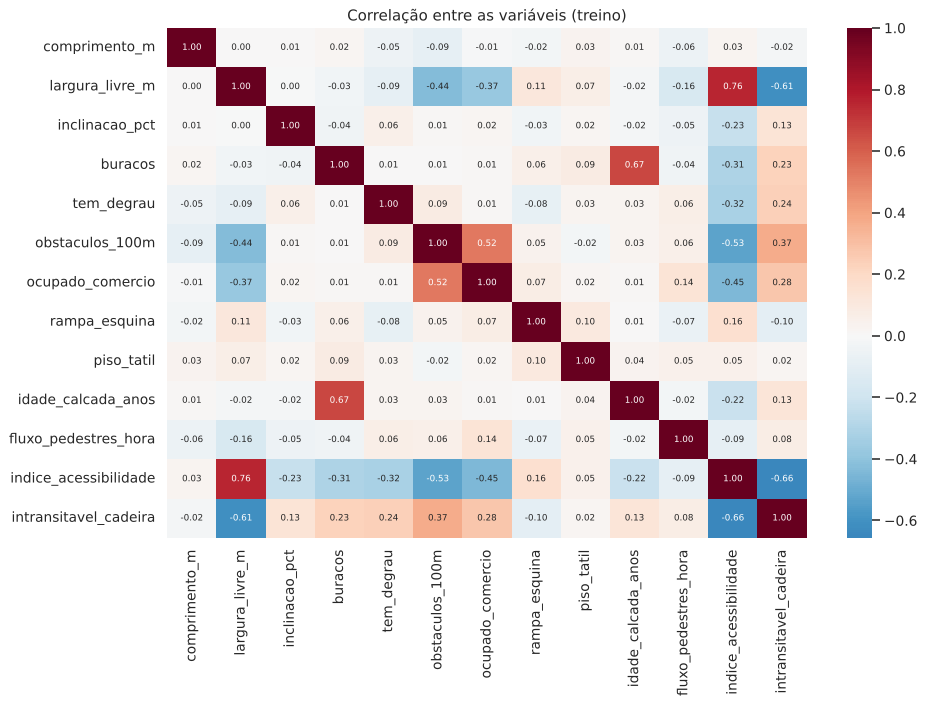

In [7]:
corr = treino[NUMERICAS + [ALVO_NUM, ALVO_BIN]].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlação entre as variáveis (treino)"); plt.tight_layout(); plt.show()

print("Correlação com o índice de acessibilidade:")
print(corr[ALVO_NUM].drop([ALVO_NUM, ALVO_BIN]).sort_values().round(2))

### 5.3 Teste de hipótese: o comércio na calçada reduz a acessibilidade?

- **H0:** o índice médio é igual em trechos ocupados e não ocupados pelo comércio.
- **H1:** o índice médio é menor nos trechos ocupados.

Usamos o teste *t* de Welch, unilateral, que não supõe variâncias iguais, com nível de significância de 5%.

In [8]:
ocup = treino.loc[treino["ocupado_comercio"] == 1, ALVO_NUM]
livre = treino.loc[treino["ocupado_comercio"] == 0, ALVO_NUM]
t, p = stats.ttest_ind(ocup, livre, equal_var=False, alternative="less")
print(f"Índice médio — ocupado: {ocup.mean():.1f} (n={len(ocup)}) | livre: {livre.mean():.1f} (n={len(livre)})")
print(f"Diferença: {ocup.mean() - livre.mean():.1f} pontos | t = {t:.2f} | p-valor = {p:.2e}")
print("Rejeitamos H0: trechos ocupados pelo comércio têm índice menor." if p < 0.05
      else "Não há evidência para rejeitar H0.")

Índice médio — ocupado: 50.0 (n=141) | livre: 70.2 (n=368)
Diferença: -20.3 pontos | t = -9.90 | p-valor = 2.14e-19
Rejeitamos H0: trechos ocupados pelo comércio têm índice menor.


## 6. Modelo 1: Regressão linear (índice de acessibilidade)

Pipeline:
- **numéricas**: preenchimento dos faltantes com a mediana do treino. Os coeficientes ficam na **unidade original**, sem padronização, para facilitar a leitura (por exemplo, "pontos por metro de largura");
- **categóricas**: *one-hot encoding*, descartando a primeira categoria para evitar colinearidade perfeita.

O pipeline é ajustado só com o treino e depois aplicado ao teste.

In [9]:
prep_linear = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUMERICAS),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAS),
])
modelo_linear = Pipeline([("prep", prep_linear), ("reg", LinearRegression())])
modelo_linear.fit(X_treino, yn_treino)

prev_treino = modelo_linear.predict(X_treino)
prev_teste = modelo_linear.predict(X_teste)

def metricas_reg(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": root_mean_squared_error(y, p), "R²": r2_score(y, p)}

base = np.full(len(yn_teste), yn_treino.mean())   # referência: prever sempre a média do treino
tabela = pd.DataFrame({"Treino": metricas_reg(yn_treino, prev_treino),
                       "Teste": metricas_reg(yn_teste, prev_teste),
                       "Referência (média)": metricas_reg(yn_teste, base)}).T.round(3)
tabela

,MAE,RMSE,R²
Treino,6.507,8.245,0.835
Teste,6.606,8.218,0.822
Referência (média),15.760,19.471,-0.000


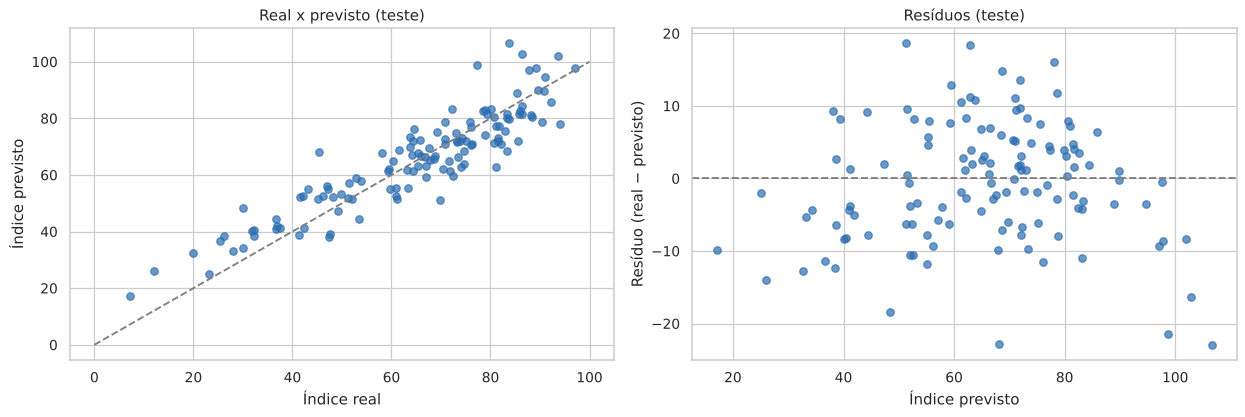

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(yn_teste, prev_teste, alpha=0.7, color="#2b6cb0")
ax[0].plot([0, 100], [0, 100], "--", c="gray")
ax[0].set(xlabel="Índice real", ylabel="Índice previsto", title="Real x previsto (teste)")
residuos = yn_teste - prev_teste
ax[1].scatter(prev_teste, residuos, alpha=0.7, color="#2b6cb0")
ax[1].axhline(0, ls="--", c="gray")
ax[1].set(xlabel="Índice previsto", ylabel="Resíduo (real − previsto)", title="Resíduos (teste)")
plt.tight_layout(); plt.show()

Intercepto: 54.3


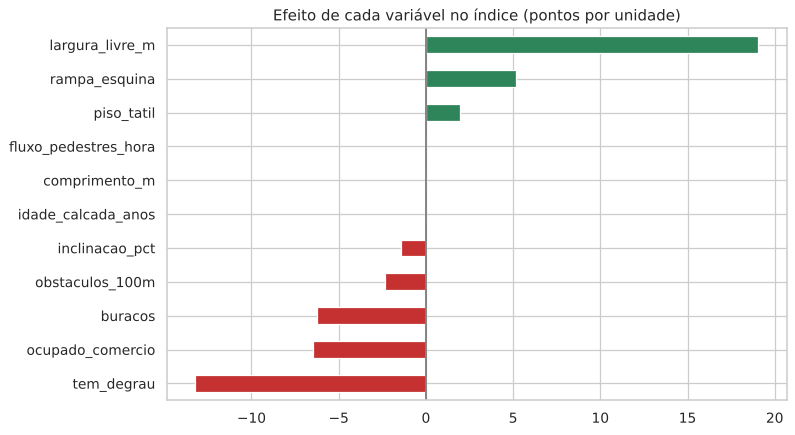

,coeficiente
comprimento_m,0.00
largura_livre_m,19.06
inclinacao_pct,-1.40
buracos,-6.25
tem_degrau,-13.22
obstaculos_100m,-2.34
ocupado_comercio,-6.46
rampa_esquina,5.14
piso_tatil,1.93
idade_calcada_anos,-0.04


In [11]:
nomes = modelo_linear.named_steps["prep"].get_feature_names_out()
coef = pd.Series(modelo_linear.named_steps["reg"].coef_, index=[n.split("__")[1] for n in nomes])
coef_num = coef[NUMERICAS].sort_values()

plt.figure(figsize=(9, 5))
coef_num.plot.barh(color=["#c53030" if v < 0 else "#2f855a" for v in coef_num])
plt.axvline(0, c="gray"); plt.title("Efeito de cada variável no índice (pontos por unidade)")
plt.tight_layout(); plt.show()
print(f"Intercepto: {modelo_linear.named_steps['reg'].intercept_:.1f}")
coef.round(2).to_frame("coeficiente")

### 6.1 Interpretação

- **Métricas (teste):** **MAE = 6,6** pontos, ou seja, o modelo erra em média 7 pontos numa escala de 0 a 100. **RMSE = 8,2**, um pouco maior porque penaliza mais os erros grandes. **R² = 0,82**: o modelo explica 82% da variação do índice. A referência que sempre prevê a média tem MAE de 15,8 e R² ≈ 0. Treino (R² = 0,84) e teste (R² = 0,82) estão muito próximos, então **não há sobreajuste**.
- **Coeficientes** (efeito de cada variável com as demais fixas):
  - **largura livre:** +19,1 pontos por metro, cerca de **+1,9 ponto a cada 10 cm** de faixa livre. Como a largura muda de rua para rua, é a variável que mais separa as ruas estreitas do Centro das avenidas;
  - **degrau:** −13,2 pontos, a maior penalidade individual;
  - **ocupação pelo comércio:** −6,5 pontos, além do que já tira da largura livre;
  - **piso quebrado:** −6,3 pontos por nível (de 0 a 3);
  - **obstáculos:** −2,3 por obstáculo a cada 100 m; **inclinação:** −1,4 por ponto percentual;
  - **rampa na esquina** (+5,1) e **piso tátil** (+1,9) aumentam o índice.
- **Variáveis sem efeito:** `comprimento_m` e `fluxo_pedestres_hora` têm coeficientes perto de zero. `idade_calcada_anos` também, porque o efeito da idade já aparece no estado do piso (`buracos`).
- **Resíduos:** espalham-se em volta de zero, sem padrão forte. Há uma leve curvatura nos índices altos: a largura tem efeito grande até cerca de 1,5 m e depois pouco muda, e uma reta não captura esse limite.

## 7. Modelo 2: Regressão logística (probabilidade de o trecho ser intransitável)

O pipeline é igual ao anterior, com **padronização** das variáveis numéricas, o que ajuda a otimização e deixa os coeficientes comparáveis entre si.
O alvo é `intransitavel_cadeira`, e o índice de acessibilidade **não** entra como variável.

In [12]:
prep_log = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), NUMERICAS),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAS),
])
modelo_log = Pipeline([("prep", prep_log), ("clf", LogisticRegression(max_iter=1000))])
modelo_log.fit(X_treino, yb_treino)

proba_teste = modelo_log.predict_proba(X_teste)[:, 1]

def metricas_clf(y, proba, limiar):
    p = (proba >= limiar).astype(int)
    return {"Precisão": precision_score(y, p), "Recall": recall_score(y, p), "F1": f1_score(y, p)}

print(f"AUC-ROC no teste: {roc_auc_score(yb_teste, proba_teste):.3f}")
pd.DataFrame({f"Limiar {l}": metricas_clf(yb_teste, proba_teste, l) for l in (0.5, 0.3)}).T.round(3)

AUC-ROC no teste: 0.938


,Precisão,Recall,F1
Limiar 0.5,0.882,0.789,0.833
Limiar 0.3,0.791,0.930,0.855


Limiar 0,5 -> VP=45 | FP=6 | FN=12 | VN=65
Limiar 0,3 -> VP=53 | FP=14 | FN=4 | VN=57


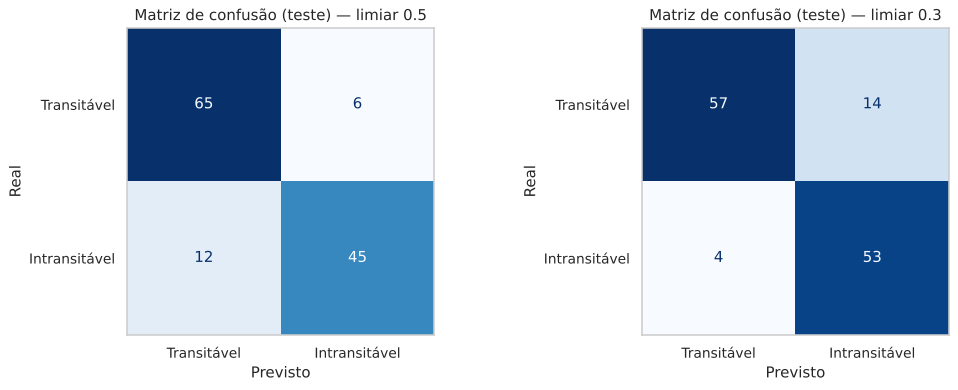

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, limiar in zip(ax, (0.5, 0.3)):
    cm = confusion_matrix(yb_teste, (proba_teste >= limiar).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Transitável", "Intransitável"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"Matriz de confusão (teste) — limiar {limiar}")
    a.grid(False); a.set_xlabel("Previsto"); a.set_ylabel("Real")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(yb_teste, (proba_teste >= 0.5).astype(int)).ravel()
print(f"Limiar 0,5 -> VP={tp} | FP={fp} | FN={fn} | VN={tn}")
tn3, fp3, fn3, tp3 = confusion_matrix(yb_teste, (proba_teste >= 0.3).astype(int)).ravel()
print(f"Limiar 0,3 -> VP={tp3} | FP={fp3} | FN={fn3} | VN={tn3}")

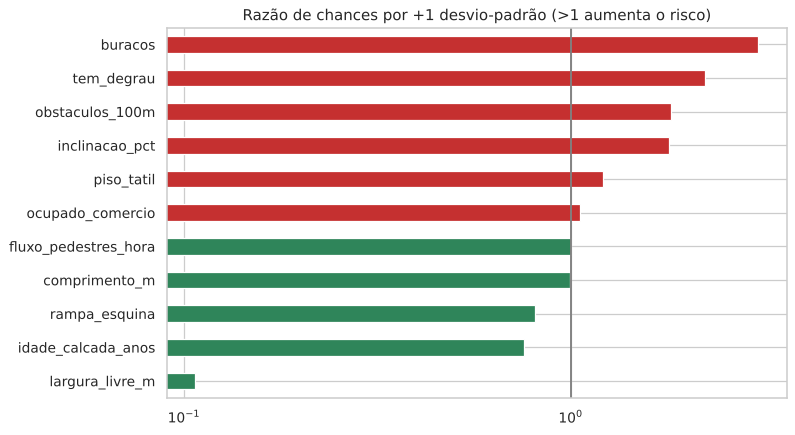

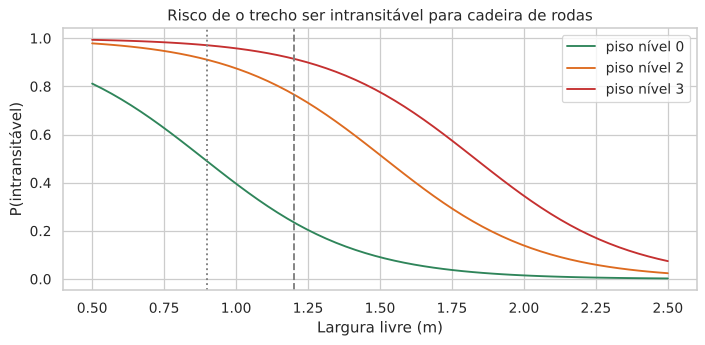

In [14]:
nomes_log = [n.split("__")[1] for n in modelo_log.named_steps["prep"].get_feature_names_out()]
coef_log = pd.Series(modelo_log.named_steps["clf"].coef_[0], index=nomes_log)
odds = np.exp(coef_log[NUMERICAS]).sort_values()

plt.figure(figsize=(9, 5))
odds.plot.barh(color=["#2f855a" if v < 1 else "#c53030" for v in odds])
plt.axvline(1, c="gray"); plt.xscale("log")
plt.title("Razão de chances por +1 desvio-padrão (>1 aumenta o risco)")
plt.tight_layout(); plt.show()

# Curva de risco: probabilidade x largura livre, com as demais variáveis no valor típico do treino
tipico = X_treino.mode().iloc[[0]].copy()
for c in NUMERICAS:
    tipico[c] = X_treino[c].median()
grade = pd.concat([tipico] * 60, ignore_index=True)
grade["largura_livre_m"] = np.linspace(0.5, 2.5, 60)
plt.figure(figsize=(8, 4))
for b, cor in zip([0, 2, 3], ["#2f855a", "#dd6b20", "#c53030"]):
    g = grade.assign(buracos=b)
    plt.plot(g["largura_livre_m"], modelo_log.predict_proba(g)[:, 1], c=cor, label=f"piso nível {b}")
plt.axvline(0.90, ls=":", c="gray"); plt.axvline(1.20, ls="--", c="gray")
plt.xlabel("Largura livre (m)"); plt.ylabel("P(intransitável)")
plt.title("Risco de o trecho ser intransitável para cadeira de rodas"); plt.legend()
plt.tight_layout(); plt.show()

### 7.1 Interpretação

- **Desempenho (teste, 128 trechos, 57 intransitáveis):** AUC-ROC = 0,94.
  - **Limiar 0,5:** precisão 0,88, recall 0,79 e F1 0,83. O modelo deixou passar **12 trechos intransitáveis** (falsos negativos) e marcou 6 trechos bons como ruins (falsos positivos).
  - **Limiar 0,3:** precisão 0,79, recall 0,93 e F1 0,86. Os falsos negativos caem de 12 para **4**, e os falsos positivos sobem de 6 para 14.
- **Qual erro é pior:** para quem usa cadeira de rodas, o **falso negativo** é o erro grave. O app diria "pode passar", e a pessoa ficaria presa ou desceria para a rua. O falso positivo só gera um desvio de alguns metros. Por isso **o app adota o limiar 0,3**: o F1 até melhora, e o número de pessoas mandadas para um trecho intransitável cai de 12 para 4.
- **Variáveis:** a **largura livre** é o fator mais forte. Cada desvio-padrão a mais (cerca de 0,6 m) multiplica a chance de o trecho ser intransitável por 0,11, ou seja, reduz a chance em quase 90%. Em seguida vêm **piso quebrado** (×3,1 por desvio-padrão), **degrau** (×2,2), **obstáculos** (×1,8) e **inclinação** (×1,8). A **rampa na esquina** reduz a chance (×0,81). A idade da calçada aparece com efeito contrário (×0,76) porque é muito correlacionada com o piso quebrado e não deve ser interpretada sozinha.
- **Curva de risco** (demais variáveis no valor típico): com piso bom, um trecho de 1,20 m (mínimo da NBR 9050) tem cerca de 24% de risco, que só fica abaixo de 10% perto de 1,50 m. Com piso muito quebrado (nível 3), o risco passa de 90% em 1,20 m. **Largura e piso precisam ser corrigidos juntos.**
- **Bairro e tipo de via** ficaram fora do gráfico. Os coeficientes deles variam bastante com esta amostra e não devem ser interpretados como causa.

## 8. Aplicação no trajeto da CalçadaLivre (Estação Suzano → Santa Casa)

Aplicamos os dois modelos aos **12 trechos de calçada** do grafo do módulo de DP. Cada trecho corresponde a uma rua (ou parte de uma rua) e tem a sua própria largura livre.
O trecho P–A (plataforma até a rua) não entra: ele é o elevador ou a escada da estação, não uma calçada.

| Nó | Ponto |
|---|---|
| P | Plataforma da Estação Suzano |
| A | Saída da estação (Rua Prudente de Moraes) |
| B | Esquina em frente à estação |
| H | Rua General Francisco Glicério (meio do comércio) |
| C | Fim do comércio da Glicério |
| I | Rua Baruel x Rua Professor Roberto David |
| J | Rua Marechal Deodoro x Rua Felício de Camargo |
| D | Rua Felício de Camargo x Av. Antônio Marques Figueira |
| K | Av. Antônio Marques Figueira (meio do trajeto) |
| E | Av. Antônio Marques Figueira x Rua Professor Roberto David |
| G | Santa Casa de Suzano (Rua Professor Roberto David, 499) |

Os valores de **índice**, **probabilidade de intransitável** e **gravidade** calculados aqui são os que o `dados.py` do módulo de DP usa.

In [15]:
trechos = pd.DataFrame([
    # (trecho, rua, bairro, tipo_via, comprimento, largura_livre, inclinação, buracos, degrau,
    #  obstáculos/100m, ocupado, rampa, piso_tátil, idade, fluxo)
    ("A-B", "Rua Prudente de Moraes (saída da estação)",  "Centro",        "coletora",   50, 1.50, 2.0, 0, 0, 1, 0, 1, 1,  8, 600),
    ("B-H", "Rua General Francisco Glicério (início)",       "Centro",        "local",     400, 0.95, 2.0, 1, 0, 4, 1, 0, 0, 20, 700),
    ("H-C", "Rua General Francisco Glicério (comércio)",     "Centro",        "local",     750, 0.75, 3.0, 2, 0, 5, 1, 0, 0, 25, 450),
    ("C-I", "Rua Baruel",                                 "Vila Figueira", "local",     500, 0.70, 4.0, 3, 0, 3, 0, 0, 0, 30, 200),
    ("I-G", "Rua Professor Roberto David (lado da Baruel)",   "Vila Figueira", "local",     350, 0.80, 5.0, 2, 1, 2, 0, 0, 0, 28, 180),
    ("H-J", "Travessa Glicério -> Marechal Deodoro",          "Centro",        "local",     250, 1.00, 2.0, 1, 0, 3, 1, 0, 0, 18, 300),
    ("C-K", "Travessa Glicério -> avenida",               "Centro",        "local",     400, 0.85, 3.0, 2, 0, 3, 0, 0, 0, 25, 150),
    ("B-J", "Rua Marechal Deodoro",                       "Centro",        "coletora",  300, 1.30, 3.0, 1, 0, 2, 0, 1, 0, 15, 500),
    ("J-D", "Rua Felício de Camargo",                     "Centro",        "coletora",  400, 1.40, 4.0, 1, 0, 2, 0, 1, 1, 12, 400),
    ("D-K", "Av. Antônio Marques Figueira (início)",      "Centro",        "arterial", 1000, 1.30, 3.0, 1, 0, 2, 0, 1, 0, 12, 350),
    ("K-E", "Av. Antônio Marques Figueira (até a Santa Casa)", "Vila Figueira", "arterial", 450, 1.60, 2.0, 0, 0, 1, 0, 1, 1, 8, 300),
    ("E-G", "Rua Professor Roberto David (lado da avenida)",  "Vila Figueira", "local",     100, 1.40, 2.0, 1, 0, 1, 0, 1, 1, 12, 250),
], columns=["trecho", "rua"] + CATEGORICAS + NUMERICAS)

LIMIAR = 0.3
def gravidade(p):                      # 1 (baixo risco) a 5 (quase certamente intransitável)
    return int(np.digitize(p, [0.10, 0.30, 0.60, 0.90]) + 1)

res = trechos[["trecho", "rua", "comprimento_m", "largura_livre_m", "buracos"]].copy()
res["indice"] = modelo_linear.predict(trechos[CATEGORICAS + NUMERICAS]).clip(0, 100).round(0).astype(int)
res["p_intransitavel"] = modelo_log.predict_proba(trechos[CATEGORICAS + NUMERICAS])[:, 1].round(2)
res["gravidade"] = res["p_intransitavel"].apply(gravidade)
res["alerta_cadeira"] = np.where(res["p_intransitavel"] >= LIMIAR, "EVITAR", "ok")
res

,trecho,rua,comprimento_m,largura_livre_m,buracos,indice,p_intransitavel,gravidade,alerta_cadeira
0,A-B,Rua Prudente de Moraes (saída da estação),50,1.50,0,93,0.04,1,ok
1,B-H,Rua General Francisco Glicério (início),400,0.95,1,50,0.80,4,EVITAR
2,H-C,Rua General Francisco Glicério (comércio),750,0.75,2,35,0.98,5,EVITAR
3,C-I,Rua Baruel,500,0.70,3,39,0.98,5,EVITAR
4,I-G,Rua Professor Roberto David (lado da Baruel),350,0.80,2,35,0.99,5,EVITAR
5,H-J,Travessa Glicério -> Marechal Deodoro,250,1.00,1,51,0.71,4,EVITAR
6,C-K,Travessa Glicério -> avenida,400,0.85,2,47,0.92,5,EVITAR
7,B-J,Rua Marechal Deodoro,300,1.30,1,77,0.21,2,ok
8,J-D,Rua Felício de Camargo,400,1.40,1,79,0.27,2,ok
9,D-K,Av. Antônio Marques Figueira (início),1000,1.30,1,71,0.20,2,ok


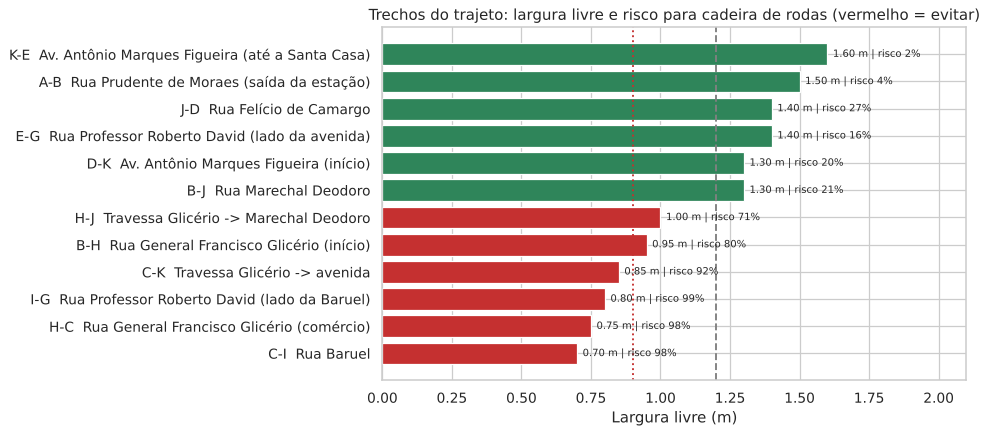

In [16]:
fig, ax = plt.subplots(figsize=(11, 5))
ordem = res.sort_values("largura_livre_m")
cores = ["#c53030" if a == "EVITAR" else "#2f855a" for a in ordem["alerta_cadeira"]]
ax.barh(ordem["trecho"] + "  " + ordem["rua"], ordem["largura_livre_m"], color=cores)
ax.axvline(0.90, ls=":", c="#c53030"); ax.axvline(1.20, ls="--", c="gray")
for y, (l, p) in enumerate(zip(ordem["largura_livre_m"], ordem["p_intransitavel"])):
    ax.text(l + 0.02, y, f"{l:.2f} m | risco {p:.0%}", va="center", fontsize=8)
ax.set_xlim(0, 2.1); ax.set_xlabel("Largura livre (m)")
ax.set_title("Trechos do trajeto: largura livre e risco para cadeira de rodas (vermelho = evitar)")
plt.tight_layout(); plt.show()

### 8.1 Valores exportados para o módulo de Dynamic Programming

A tabela abaixo é copiada para o `dados.py`:
- `indice` vira o custo do trecho no Dijkstra;
- `p_intransitavel` bloqueia o trecho para cadeira de rodas quando passa do limiar de 0,3;
- `gravidade` entra no benefício da mochila 0/1 de reformas.

A última célula confere que os valores do `dados.py` são exatamente os previstos aqui.

In [17]:
# Valores que estão no dados.py do módulo de DP (trecho: (indice, p_intransitavel, gravidade))
DADOS_PY = {'A-B': (93, 0.04, 1),
            'B-H': (50, 0.8, 4),
            'H-C': (35, 0.98, 5),
            'C-I': (39, 0.98, 5),
            'I-G': (35, 0.99, 5),
            'H-J': (51, 0.71, 4),
            'C-K': (47, 0.92, 5),
            'B-J': (77, 0.21, 2),
            'J-D': (79, 0.27, 2),
            'D-K': (71, 0.2, 2),
            'K-E': (91, 0.02, 1),
            'E-G': (80, 0.16, 2)}

exportado = {t: (int(i), float(p), int(g)) for t, i, p, g in
             res[["trecho", "indice", "p_intransitavel", "gravidade"]].itertuples(index=False)}
diferentes = {t: (DADOS_PY.get(t), v) for t, v in exportado.items() if DADOS_PY.get(t) != v}
print("Valores do dados.py iguais aos previstos pelos modelos:", not diferentes)
if diferentes:
    print("Diferenças (dados.py, modelo):", diferentes)
res[["trecho", "indice", "p_intransitavel", "gravidade"]]

Valores do dados.py iguais aos previstos pelos modelos: True


,trecho,indice,p_intransitavel,gravidade
0,A-B,93,0.04,1
1,B-H,50,0.80,4
2,H-C,35,0.98,5
3,C-I,39,0.98,5
4,I-G,35,0.99,5
5,H-J,51,0.71,4
6,C-K,47,0.92,5
7,B-J,77,0.21,2
8,J-D,79,0.27,2
9,D-K,71,0.20,2


### 8.2 Simulação de reforma: quanto melhora cada trecho?

Simulamos a reforma dos trechos marcados como **EVITAR**: faixa livre ampliada para 1,50 m, piso recomposto (nível 0), comércio fora da faixa livre, degrau removido, rampa nas esquinas e piso tátil.
O ganho de índice e a queda de risco mostram o benefício de cada obra para a mochila 0/1 do módulo de DP.

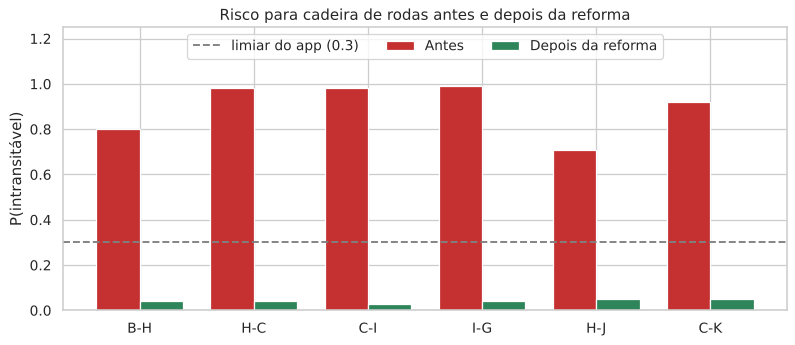

,rua,indice_antes,P_antes,indice_depois,P_depois,ganho_indice
trecho,,,,,,
B-H,Rua General Francisco Glicério (início),50,0.80,87,0.04,37
H-C,Rua General Francisco Glicério (comércio),35,0.98,85,0.04,50
C-I,Rua Baruel,39,0.98,85,0.03,46
I-G,Rua Professor Roberto David (lado da Baruel),35,0.99,83,0.04,48
H-J,Travessa Glicério -> Marechal Deodoro,51,0.71,85,0.05,34
C-K,Travessa Glicério -> avenida,47,0.92,83,0.05,36


In [18]:
evitar = res.loc[res["alerta_cadeira"] == "EVITAR", "trecho"]
reforma = trechos[trechos["trecho"].isin(evitar)].copy()
reforma[["largura_livre_m", "buracos", "ocupado_comercio", "tem_degrau", "rampa_esquina", "piso_tatil"]] = [1.50, 0, 0, 0, 1, 1]
reforma["obstaculos_100m"] = 1

sim = res.set_index("trecho").loc[reforma["trecho"], ["rua", "indice", "p_intransitavel"]]
sim = sim.rename(columns={"indice": "indice_antes", "p_intransitavel": "P_antes"})
sim["indice_depois"] = modelo_linear.predict(reforma[CATEGORICAS + NUMERICAS]).clip(0, 100).round(0).astype(int)
sim["P_depois"] = modelo_log.predict_proba(reforma[CATEGORICAS + NUMERICAS])[:, 1].round(2)
sim["ganho_indice"] = sim["indice_depois"] - sim["indice_antes"]

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(sim)); w = 0.38
ax.bar(x - w/2, sim["P_antes"], w, label="Antes", color="#c53030")
ax.bar(x + w/2, sim["P_depois"], w, label="Depois da reforma", color="#2f855a")
ax.axhline(LIMIAR, ls="--", c="gray", label=f"limiar do app ({LIMIAR})")
ax.set_xticks(x, sim.index); ax.set_ylabel("P(intransitável)"); ax.set_ylim(0, 1.25)
ax.set_title("Risco para cadeira de rodas antes e depois da reforma"); ax.legend(loc="upper center", ncol=3)
plt.tight_layout(); plt.show()
sim

## 9. Recomendações

As previsões levam a estas ações:

1. **Na CalçadaLivre, tirar a cadeira de rodas das ruas estreitas do comércio.** Os trechos da Rua General Francisco Glicério, da Rua Baruel, da Rua Professor Roberto David pelo lado da Baruel e as duas travessas têm risco de intransitável entre 71% e 99%. Todos passam do limiar de 0,3. O app deve indicar a rota pela Rua Marechal Deodoro, Rua Felício de Camargo e Av. Antônio Marques Figueira, com cerca de 2.330 m. São 250 m a mais, mas todos os trechos têm risco abaixo de 30%.
2. **Usar as previsões no lugar de valores fixos.** No `dados.py`, o índice previsto é o custo do trecho no Dijkstra, a probabilidade bloqueia o trecho para cadeira de rodas e a gravidade entra na mochila de reformas. Cada trecho novo mapeado já recebe esses três valores, sem precisar de avaliação manual.
3. **Priorizar a reforma da Glicério e da chegada à Santa Casa pela Baruel.** São os trechos com menor índice (35 a 50) e maior risco. A simulação mostra que, com faixa livre de 1,50 m e piso recomposto, o risco cai para cerca de 4% e o índice passa de 80. Na mochila 0/1 do DP, essa gravidade vira o benefício que decide o que reformar dentro do orçamento.
4. **Fiscalizar a ocupação da calçada pelo comércio.** O teste de hipótese mostrou que trechos ocupados têm índice cerca de 20 pontos menor. Na Glicério, a largura livre cai abaixo de 1 m. Liberar a faixa livre é uma ação de **custo baixo**: depende de fiscalização, não de obra.
5. **Definir a meta de largura por rua, não uma regra única.** As ruas do Centro e da Vila Figueira têm calçadas bem mais estreitas que as avenidas. O mínimo legal é 1,20 m (NBR 9050), mas a curva de risco mostra que, com piso quebrado, 1,20 m não basta. Nas ruas estreitas, a meta deve ser cerca de 1,50 m livres com piso recomposto, que é o cenário simulado na seção 8.2.

### Impactos esperados
- Para **Seu Antônio** (cadeirante), **Camila** (carrinho de bebê) e **Dona Neide** (idosa), a rota indicada chega à Santa Casa sem obrigar ninguém a descer para a rua.
- A prefeitura passa a gastar primeiro onde o modelo indica maior risco para mais pessoas por dia.

## 10. Limitações

- **Base simulada:** os dados foram gerados pelo grupo a partir de regras e da NBR 9050. As larguras típicas de cada rua também são estimativas. As métricas mostram que o método funciona, mas os coeficientes reais só virão de uma **auditoria de campo** (ou de relatos dos usuários do app) no trajeto Estação Suzano → Santa Casa.
- **Relação não linear:** o efeito da largura livre diminui acima de cerca de 1,5 m, e a regressão linear não captura esse limite. Uma variável como `min(largura, 1,5)` ou um modelo de árvore pode melhorar o ajuste.
- **Variável-alvo subjetiva:** o índice depende de quem avalia, e "conseguir passar" depende da cadeira e da pessoa. Vale ter mais de um avaliador por trecho.
- **Limiar de decisão:** o limiar de 0,3 aumenta os falsos positivos, ou seja, desvios desnecessários. O valor deve ser revisto com os usuários.
- **Dados que mudam:** obras, barracas e o elevador da estação mudam o estado dos trechos ao longo do tempo. O modelo precisa ser atualizado periodicamente, e o cache de rotas do DP precisa ser limpo quando isso acontece.